# The Problem 
    
#### Informatica Job Failure Analysis 
    Informatica is an ETL Tool which is used to transform data from Source to destination/ target. Like transforming data from an HR application to either database or downstream applications. The data obtained from source is mostly raw. Informatica Jobs extract this data, transform the data by sending only relevant data and finally load the data to database to other applications. These are carried out by jobs which run in the background. Each jobs constitutes a workflow sessions and mappings in it. The role of an ETL developer is to create jobs and workflow session and ensure proper running of each of them
    
    1. Mapping:- The structure/ design  of the data(columns) is present in mapping. It is prefixed by m_.
    2. Session:- The configurations like Source File, Target File, Connections of the DB or Applications is done in session. It is prefixed by s_. Many mappings together form session.
    3. Workflows:- Many sessions are part of the workflow . It consists of the connection string details. Scheduling the task is done here. It is prefixed by wf_. 

    When a job is being scheduled then the workflow runs . Inside the workflow there are many sessions connected to each other. And each session is made up of mapping. If the job succeeds the data is transferred to the target, otherwise no data is transferred. Through this dataset we need to predict which job is likely to succeed or fail by training our model. For doing this, we make use of several features like Mapping Name, Session Name, Workflow name, First_Error_logm , Session Timestamp, Last Error Code,Successful_Rows, Failed_Rows and so on.
    
    Our end goal is to predict which jobs are most likely to fail in the near future
    
*For more infomation on informtica jobs, refer https://www.edureka.co/blog/informatica-etl/*

### Importing Libraries

In [6]:
# Importing libraries
import pandas as pd
pd.set_option('display.max_columns',45)
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import numpy as np
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

In [7]:
info_jobs = pd.read_csv('Export_EDW.csv')
print('Shape: ',info_jobs.shape)
info_jobs.head()

Shape:  (79290, 27)


,SUBJECT_AREA,SUBJECT_ID,SESSION_NAME,SESSION_ID,SESSION_INSTANCE_NAME,SUCCESSFUL_ROWS,FAILED_ROWS,SUCCESSFUL_SOURCE_ROWS,FAILED_SOURCE_ROWS,FIRST_ERROR_CODE,FIRST_ERROR_MSG,LAST_ERROR_CODE,LAST_ERROR,RUN_STATUS_CODE,ACTUAL_START,SESSION_TIMESTAMP,SESSION_LOG_FILE,BAD_FILE_LOCATION,TASK_VERSION_NUMBER,WORKFLOW_VERSION_NUMBER,WORKFLOW_NAME,MAPPING_NAME,TOTAL_ERR,WORKFLOW_ID,WORKFLOW_RUN_ID,WORKLET_RUN_ID,INSTANCE_ID
0,edw_fixes,20,s_m_EDW_STG_CPU_UTILIZATION,19850,s_m_EDW_STG_CPU_UTILIZATION,9,0,9,0,0,No errors encountered.,0,NaN,1,3/25/2019 0:00,3/25/2019 0:00,/edw/Informatica/server/infa_shared/SessLogs/s...,NaN,1,1,wf_EDWSTG_CPU_UTILIZATION,m_EDWSTG_CPU_UTILIZATION,0,19848,1889968,0,25516
1,edw_fixes,20,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION_new,15228,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION_new,0,0,0,0,0,NaN,0,NaN,2,3/25/2019 0:00,3/25/2019 0:00,NaN,NaN,1,1,wf_EDWSTG_E1V9_STATUS_VALIDATION,NaN,0,15226,1889969,0,21116
2,edw_fixes,20,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,15227,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,1135,0,1224386,0,0,No errors encountered.,0,NaN,1,3/25/2019 0:00,3/25/2019 0:00,/edw/Informatica/server/infa_shared/SessLogs/s...,NaN,1,1,wf_EDWSTG_E1V9_STATUS_VALIDATION,m_EDWSTG_STG_E1V9_STATUS_VALIDATION,0,15226,1889969,0,21115
3,edw_fixes,20,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,15227,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,1134,0,1222642,0,0,No errors encountered.,0,NaN,1,3/25/2019 0:00,3/25/2019 0:00,/edw/Informatica/server/infa_shared/SessLogs/s...,NaN,1,1,wf_EDWSTG_E1V9_STATUS_VALIDATION,m_EDWSTG_STG_E1V9_STATUS_VALIDATION,0,15226,1889972,0,21115
4,edw_fixes,20,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION_new,15228,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION_new,0,0,0,0,0,NaN,0,NaN,2,3/25/2019 0:00,3/25/2019 0:00,NaN,NaN,1,1,wf_EDWSTG_E1V9_STATUS_VALIDATION,NaN,0,15226,1889972,0,21116


In [8]:
info_jobs.describe(include='object')

,SUBJECT_AREA,SESSION_NAME,SESSION_INSTANCE_NAME,FIRST_ERROR_MSG,LAST_ERROR,ACTUAL_START,SESSION_TIMESTAMP,SESSION_LOG_FILE,WORKFLOW_NAME,MAPPING_NAME
count,79290,79290,79290,73473,258,79290,79290,73473,79290,73473
unique,18,2026,2056,224,132,31,31,1955,219,1702
top,edw,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION_new,No errors encountered.,FR_3000 Error opening file [/edw/edw_files/wip...,3/8/2019 0:00,3/8/2019 0:00,/edw/Informatica/server/infa_shared/SessLogs/s...,wf_EDWSTG_E1V9_STATUS_VALIDATION,m_EDWSTG_STG_E1V9_STATUS_VALIDATION
freq,46532,2876,2876,71370,39,3797,3790,2876,5752,2876


In [9]:
info_jobs.describe()

,SUBJECT_ID,SESSION_ID,SUCCESSFUL_ROWS,FAILED_ROWS,SUCCESSFUL_SOURCE_ROWS,FAILED_SOURCE_ROWS,FIRST_ERROR_CODE,LAST_ERROR_CODE,RUN_STATUS_CODE,BAD_FILE_LOCATION,TASK_VERSION_NUMBER,WORKFLOW_VERSION_NUMBER,TOTAL_ERR,WORKFLOW_ID,WORKFLOW_RUN_ID,WORKLET_RUN_ID,INSTANCE_ID
count,79290.000000,79290.000000,7.929000e+04,7.929000e+04,7.929000e+04,79290.000000,79290.000000,79290.000000,79290.000000,0.0,79290.0,79290.0,79290.000000,79290.000000,7.929000e+04,7.929000e+04,79290.000000
mean,37.003872,12757.829197,8.909654e+05,4.224615e+01,1.536212e+06,2.103241,283.967890,27.663652,1.080351,NaN,1.0,1.0,2.082633,12017.834557,1.885464e+06,1.287080e+06,18524.664901
std,28.070167,4002.747519,7.608715e+06,5.275994e+03,1.211419e+07,85.839525,2046.925811,781.413270,0.289061,NaN,0.0,0.0,85.733311,4200.135387,6.512731e+03,8.776391e+05,4840.492889
min,19.000000,5144.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,1.000000,NaN,1.0,1.0,0.000000,5151.000000,1.874095e+06,0.000000e+00,6567.000000
25%,19.000000,9304.000000,1.000000e+00,0.000000e+00,1.300000e+01,0.000000,0.000000,0.000000,1.000000,NaN,1.0,1.0,0.000000,9365.000000,1.879908e+06,0.000000e+00,16601.000000
50%,19.000000,13530.000000,1.130000e+03,0.000000e+00,5.298500e+03,0.000000,0.000000,0.000000,1.000000,NaN,1.0,1.0,0.000000,12981.000000,1.885568e+06,1.880400e+06,19111.000000
75%,70.000000,15307.000000,5.359100e+04,0.000000e+00,1.991752e+05,0.000000,0.000000,0.000000,1.000000,NaN,1.0,1.0,0.000000,15226.000000,1.891106e+06,1.888464e+06,21947.000000
max,116.000000,20167.000000,3.304670e+08,1.060442e+06,7.276993e+08,8992.000000,36401.000000,44127.000000,5.000000,NaN,1.0,1.0,8992.000000,20183.000000,1.896760e+06,1.896761e+06,25687.000000


### Data Description

1. SUBJECT_AREA: Subject Area the job belongs to like HR, CRM, etc..
2. SUBJECT_ID: Unique ID of the Subject Area
3. SESSION_NAME: Name associated with Informatica sessions used for configurations. It is prefixed by s_.
4. SESSION_INSTANCE_NAME: Name associated with Informatica sessions used for configurations. It is prefixed by s_.
5. SUCESSFUL_ROWS: The rows which are successfully loaded to target systems.
6. FAILED_ROWS: Rows did not load successfully to target systems.
7. SUCCESSFUL_SOURCE_ROWS: The rows which are successfully extracted from Source system.
8. FAILED_SOURCE_ROWS: The rows which are not successfully extracted from Source system
9. FIRST_ERROR_CODE: The error status in case of failure when extracted from source.
10. FIRST_ERROR_MSG: The Error message being popped up on job failure.
11. LAST_ERROR_CODE: The error status in case of failure when loaded to destination.
12. LAST_ERROR:
13. RUN_STATUS_CODE : The status code states whether the job successfully transmitted data or was it a failure.
14. ACTUAL_START: The time the Informatica job starts.
15. SESSION_TIMESTAMP : The total time the job took to run is in the timestamp.
16. SESSION_LOG_FILE: When a session runs a log file is generated , which acts like a Trace file and which gives a detailed understanding of the job.
17. BAD_FILE_LOCATION : The bad file contains rows that are rejected when writing to the database.
18. TASK_VERSION_NUMBER : Version Number of the task
19. WORKFLOW_VERSION_NUMBER: Version Number in which the workflow runs
20. WORKFLOW_NAME: Name of the workflow used to execute the mappings. It is prefixed by wf_.
21. MAPPING_NAME: Mapping is the design of the Informatica Job. It is prefixed by m_.
22. TOTAL_ERR : The Error occured during Job run.
23. WORKFLOW_ID : The unique identification number associated with the Workflow.
24. WORKFLOW_RUN_ID: On execution of workflow a run_id is associated with it, which is called Workflow_Run_ID.
25. WORKLET_RUN_ID: The ID generated on execution of a worklet is called Worklet_Run_Id.
26. INSTANCE_ID : The object associated with the Workflow has an unique ID called an Instance ID.
    

In [10]:
info_jobs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79290 entries, 0 to 79289
Data columns (total 27 columns):
SUBJECT_AREA               79290 non-null object
SUBJECT_ID                 79290 non-null int64
SESSION_NAME               79290 non-null object
SESSION_ID                 79290 non-null int64
SESSION_INSTANCE_NAME      79290 non-null object
SUCCESSFUL_ROWS            79290 non-null int64
FAILED_ROWS                79290 non-null int64
SUCCESSFUL_SOURCE_ROWS     79290 non-null int64
FAILED_SOURCE_ROWS         79290 non-null int64
FIRST_ERROR_CODE           79290 non-null int64
FIRST_ERROR_MSG            73473 non-null object
LAST_ERROR_CODE            79290 non-null int64
LAST_ERROR                 258 non-null object
RUN_STATUS_CODE            79290 non-null int64
ACTUAL_START               79290 non-null object
SESSION_TIMESTAMP          79290 non-null object
SESSION_LOG_FILE           73473 non-null object
BAD_FILE_LOCATION          0 non-null float64
TASK_VERSION_NUMBER    

    There are null values in column "BAD_FILE_LOCATION" . This column specifies that it is a flat file (csv,txt,xls) which consists of rejected records which not sent to target. 

    Earlier we had used describe twice, why? feel free to go back a few cells and compare

    The describe option shows all descriptive statistics for numeric columns unless specified. So, it is up to us to specify if we would like to look at stats for the non-numeric types as well. While we are at it, why can't we just use "all" instead of specific data type?

In [14]:
#We see that the columns ending with suffix '_ID' are not much relevant in further analysis. Hence, we can drop these columns.
# Dropping cols ending with '_ID'
info_jobs_1 = info_jobs[info_jobs.columns[~info_jobs.columns.str.endswith('_ID')]].copy(deep=True)

In [15]:
info_jobs_1.shape
##After dropping the _ID cols the columns get reduced from 27 to 21.

(79290, 21)

In [16]:
info_jobs_1.columns

Index(['SUBJECT_AREA', 'SESSION_NAME', 'SESSION_INSTANCE_NAME',
       'SUCCESSFUL_ROWS', 'FAILED_ROWS', 'SUCCESSFUL_SOURCE_ROWS',
       'FAILED_SOURCE_ROWS', 'FIRST_ERROR_CODE', 'FIRST_ERROR_MSG',
       'LAST_ERROR_CODE', 'LAST_ERROR', 'RUN_STATUS_CODE', 'ACTUAL_START',
       'SESSION_TIMESTAMP', 'SESSION_LOG_FILE', 'BAD_FILE_LOCATION',
       'TASK_VERSION_NUMBER', 'WORKFLOW_VERSION_NUMBER', 'WORKFLOW_NAME',
       'MAPPING_NAME', 'TOTAL_ERR'],
      dtype='object')

In [18]:
info_jobs_1.drop(['SESSION_INSTANCE_NAME','TASK_VERSION_NUMBER','WORKFLOW_VERSION_NUMBER','SESSION_LOG_FILE'],axis = 1,inplace=True)
info_jobs_1.shape

(79290, 17)

    How is above drop statement justified?

    The instance name, task version number and Workflow version number clearly do not have anything to do with a failure. session_log_file denotes the path where a log file is stored, so there is no effect there as well and hence we can safely drop them

### Data Cleaning

In [19]:
# Let us find out the missing values
info_jobs_1.isnull().sum()

SUBJECT_AREA                  0
SESSION_NAME                  0
SUCCESSFUL_ROWS               0
FAILED_ROWS                   0
SUCCESSFUL_SOURCE_ROWS        0
FAILED_SOURCE_ROWS            0
FIRST_ERROR_CODE              0
FIRST_ERROR_MSG            5817
LAST_ERROR_CODE               0
LAST_ERROR                79032
RUN_STATUS_CODE               0
ACTUAL_START                  0
SESSION_TIMESTAMP             0
BAD_FILE_LOCATION         79290
WORKFLOW_NAME                 0
MAPPING_NAME               5817
TOTAL_ERR                     0
dtype: int64

In [20]:
info_jobs_1[info_jobs_1['MAPPING_NAME'].isnull()].head(10)

,SUBJECT_AREA,SESSION_NAME,SUCCESSFUL_ROWS,FAILED_ROWS,SUCCESSFUL_SOURCE_ROWS,FAILED_SOURCE_ROWS,FIRST_ERROR_CODE,FIRST_ERROR_MSG,LAST_ERROR_CODE,LAST_ERROR,RUN_STATUS_CODE,ACTUAL_START,SESSION_TIMESTAMP,BAD_FILE_LOCATION,WORKFLOW_NAME,MAPPING_NAME,TOTAL_ERR
1,edw_fixes,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION_new,0,0,0,0,0,NaN,0,NaN,2,3/25/2019 0:00,3/25/2019 0:00,NaN,wf_EDWSTG_E1V9_STATUS_VALIDATION,NaN,0
4,edw_fixes,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION_new,0,0,0,0,0,NaN,0,NaN,2,3/25/2019 0:00,3/25/2019 0:00,NaN,wf_EDWSTG_E1V9_STATUS_VALIDATION,NaN,0
10,edw,s_m_STG_STG_F1755_E1,0,0,0,0,0,NaN,0,NaN,2,3/26/2019 0:00,3/26/2019 0:00,NaN,wf_STAGE_E1,NaN,0
20,edw,s_m_STG_STG_F40051_E1,0,0,0,0,0,NaN,0,NaN,2,3/26/2019 0:00,3/26/2019 0:00,NaN,wf_STAGE_E1,NaN,0
30,edw,s_m_EDW_F_SLS_ORD_E1,0,0,0,0,0,NaN,0,NaN,2,3/26/2019 0:00,3/26/2019 0:00,NaN,wf_LOAD_SALES_ORDER_E1,NaN,0
32,edw,s_m_EDW_F_SLS_ORD_E1_upd_ord_attrib_quote,0,0,0,0,0,NaN,0,NaN,2,3/26/2019 0:00,3/26/2019 0:00,NaN,wf_LOAD_SALES_ORDER_E1,NaN,0
64,edw_fixes,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION_new,0,0,0,0,0,NaN,0,NaN,2,3/26/2019 0:00,3/26/2019 0:00,NaN,wf_EDWSTG_E1V9_STATUS_VALIDATION,NaN,0
75,edw_fixes,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION_new,0,0,0,0,0,NaN,0,NaN,2,3/26/2019 0:00,3/26/2019 0:00,NaN,wf_EDWSTG_E1V9_STATUS_VALIDATION,NaN,0
78,fishnet,s_m_STG_FF_SLS_ORD_HOLD_EXCLUDE,0,0,0,0,0,NaN,0,NaN,2,3/26/2019 0:00,3/26/2019 0:00,NaN,wf_LOAD_SALES_ORDER_HOLD,NaN,0
94,Integrations,s_m_EDW_DIM_PROD_HIER_INFOR,0,0,0,0,0,NaN,0,NaN,2,3/26/2019 0:00,3/26/2019 0:00,NaN,wf_LOAD_EDW_INFOR,NaN,0


    Looks like there are duplicate values in the data. Let's remove them

In [104]:
# Retriving only unique rows
info_jobs_unique = info_jobs_1.drop_duplicates().copy(deep=True)

In [105]:
info_jobs_unique.shape

(64491, 17)

In [106]:
print("Info_jobs with duplicate records",info_jobs_1.shape)
print("Info_jobs with unique records", info_jobs_unique.shape)
print ("% of duplicates is ", 1. * (len(info_jobs_1) - len(info_jobs_unique)) / ( len(info_jobs_1)))

Info_jobs with duplicate records (79290, 17)
Info_jobs with unique records (64491, 17)
% of duplicates is  0.18664396519107077


    The column "BAD_FILE_LOCATION" and "LAST_ERROR" have too many null values and hence will not be of much use for further analysis. So we will drop them

In [107]:
info_jobs_unique.drop(['BAD_FILE_LOCATION','LAST_ERROR'],axis=1,inplace=True)
info_jobs_unique.head()

,SUBJECT_AREA,SESSION_NAME,SUCCESSFUL_ROWS,FAILED_ROWS,SUCCESSFUL_SOURCE_ROWS,FAILED_SOURCE_ROWS,FIRST_ERROR_CODE,FIRST_ERROR_MSG,LAST_ERROR_CODE,RUN_STATUS_CODE,ACTUAL_START,SESSION_TIMESTAMP,WORKFLOW_NAME,MAPPING_NAME,TOTAL_ERR
0,edw_fixes,s_m_EDW_STG_CPU_UTILIZATION,9,0,9,0,0,No errors encountered.,0,1,3/25/2019 0:00,3/25/2019 0:00,wf_EDWSTG_CPU_UTILIZATION,m_EDWSTG_CPU_UTILIZATION,0
1,edw_fixes,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION_new,0,0,0,0,0,NaN,0,2,3/25/2019 0:00,3/25/2019 0:00,wf_EDWSTG_E1V9_STATUS_VALIDATION,NaN,0
2,edw_fixes,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,1135,0,1224386,0,0,No errors encountered.,0,1,3/25/2019 0:00,3/25/2019 0:00,wf_EDWSTG_E1V9_STATUS_VALIDATION,m_EDWSTG_STG_E1V9_STATUS_VALIDATION,0
3,edw_fixes,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,1134,0,1222642,0,0,No errors encountered.,0,1,3/25/2019 0:00,3/25/2019 0:00,wf_EDWSTG_E1V9_STATUS_VALIDATION,m_EDWSTG_STG_E1V9_STATUS_VALIDATION,0
5,edw,s_m_STG_STG_F4102_E1,177761,0,177761,0,0,No errors encountered.,0,1,3/26/2019 0:00,3/26/2019 0:00,wf_STAGE_E1,m_STG_STG_F4102_E1,0


In [108]:
info_jobs_unique.shape

(64491, 15)

    There are null values in other columns too, try thinking ways to deal with them

In [109]:
# Imputing the null values in object data types using 'mode'
cols = ["MAPPING_NAME","FIRST_ERROR_MSG"]
info_jobs_unique[cols].fillna(info_jobs_unique.mode().iloc[0],inplace=True)

/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/pandas/core/generic.py:6287: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._update_inplace(new_data)


In [110]:
# Checking the missing values 
info_jobs_unique.isnull().sum()

SUBJECT_AREA                 0
SESSION_NAME                 0
SUCCESSFUL_ROWS              0
FAILED_ROWS                  0
SUCCESSFUL_SOURCE_ROWS       0
FAILED_SOURCE_ROWS           0
FIRST_ERROR_CODE             0
FIRST_ERROR_MSG           1922
LAST_ERROR_CODE              0
RUN_STATUS_CODE              0
ACTUAL_START                 0
SESSION_TIMESTAMP            0
WORKFLOW_NAME                0
MAPPING_NAME              1922
TOTAL_ERR                    0
dtype: int64

In [111]:
for col in info_jobs_unique.columns:
    print(col,':')
    print(info_jobs_unique[col].value_counts(),'\n\n\n')

SUBJECT_AREA :
edw                       37143
fishnet                    5909
Integrations               5863
customer_data_mart         3685
edm                        3280
edw_fixes                  3202
Life_Ops_Metrics           1322
SKU_reporting              1220
cas                         936
Quality_BI                  815
APP_LPG_SAC                 256
edwrnd                      231
VNTI                        198
DTD_Search_Index_build      150
eCatalog                    145
edw_mnt                     100
APP_LPG_SDW                  32
edw_d4_fixes                  4
Name: SUBJECT_AREA, dtype: int64 



SESSION_NAME :
s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION         2840
s_m_FF_STG_START_SOURCE_STG_ap                 358
s_m_FF_P2009_TRAX_PEM_alert                    239
s_m_FF_STG_START_SOURCE_STG_na                 217
s_m_FF_STG_START_SOURCE_STG_eu                 211
                                              ... 
s_m_SAC_775_GEN_LAB_SUPPLY_STG                   1


### Exploratory Data Analysis(EDA)

    From , this url : https://network.informatica.com/thread/44437 we come to know the various status code.
<ul>
<li>1 = Suceeded</li>
<li>2 = Disabled</li>
<li>3 = Failed</li>
<li>4 = Stopped</li>
<li>5 = Aborted</li>
</ul>

In [112]:
info_jobs_unique['RUN_STATUS_CODE'].value_counts()

1    62360
2     1901
3      176
4       50
5        4
Name: RUN_STATUS_CODE, dtype: int64

In [113]:
info_jobs_unique['RUN_STATUS_CODE'].replace(to_replace=[2,3,4,5],value=[0]*4,inplace=True)

In [114]:
1. * (info_jobs_unique['RUN_STATUS_CODE'].value_counts()) / len(info_jobs_unique)

1    0.966957
0    0.033043
Name: RUN_STATUS_CODE, dtype: float64

    We are essentially converting all codes 2,3,4,5 to 0, doesn't it cause information loss?


    It doesn't in this case because we are only interested in success or failure not the failure kind

    In the 0.03% failure which 'Subject Area' is failing the most.

In [115]:
# Let us compare the success rate across 'Subject_Area' and see if there is any difference
subject_area_status = pd.crosstab(info_jobs_unique.SUBJECT_AREA,info_jobs_unique.RUN_STATUS_CODE).apply(lambda x : x/x.sum() * 100,axis=1)
subject_area_status

RUN_STATUS_CODE,0,1
SUBJECT_AREA,,
APP_LPG_SAC,3.906250,96.093750
APP_LPG_SDW,0.000000,100.000000
DTD_Search_Index_build,6.666667,93.333333
Integrations,0.818694,99.181306
Life_Ops_Metrics,13.767020,86.232980
Quality_BI,0.000000,100.000000
SKU_reporting,0.573770,99.426230
VNTI,0.000000,100.000000
cas,1.816239,98.183761


In [116]:
subject_area_status = subject_area_status[0]
subject_area_status

SUBJECT_AREA
APP_LPG_SAC                3.906250
APP_LPG_SDW                0.000000
DTD_Search_Index_build     6.666667
Integrations               0.818694
Life_Ops_Metrics          13.767020
Quality_BI                 0.000000
SKU_reporting              0.573770
VNTI                       0.000000
cas                        1.816239
customer_data_mart         2.822252
eCatalog                   0.000000
edm                        2.378049
edw                        4.062677
edw_d4_fixes               0.000000
edw_fixes                  1.811368
edw_mnt                   20.000000
edwrnd                     0.000000
fishnet                    1.489254
Name: 0, dtype: float64

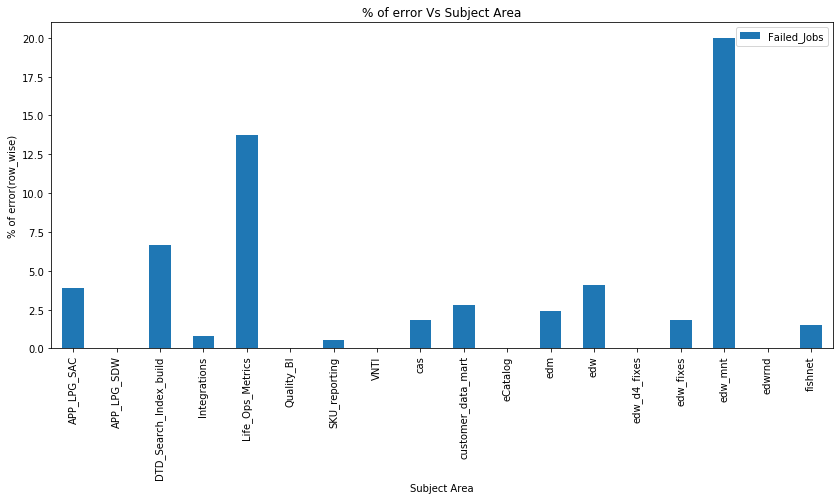

In [117]:
subject_area_status.plot.bar(label='Failed_Jobs' , figsize = (14,6))
plt.xlabel('Subject Area')
plt.ylabel('% of error(row_wise)')
plt.title('% of error Vs Subject Area')
plt.legend()
plt.show()

# take care of font of text and rotation of X lables

    We can observe from the above graph that the Subject_Area 'edw_mnt', 'Life_Ops_Metrics' and then 'DTD_Search_Index_build' have higher error rates.

In [118]:
# Let us compare 'SUBJECT_AREA' with 'RUN_STATUS_CODE' in row-wise
subject_row_wise = pd.crosstab(info_jobs_unique.SUBJECT_AREA,info_jobs_unique.RUN_STATUS_CODE).apply(lambda x : x/x.sum() * 100,axis=0)
subject_row_wise

RUN_STATUS_CODE,0,1
SUBJECT_AREA,,
APP_LPG_SAC,0.469263,0.394484
APP_LPG_SDW,0.000000,0.051315
DTD_Search_Index_build,0.469263,0.224503
Integrations,2.252464,9.324888
Life_Ops_Metrics,8.540591,1.828095
Quality_BI,0.000000,1.306928
SKU_reporting,0.328484,1.945157
VNTI,0.000000,0.317511
cas,0.797748,1.473701


In [119]:
subject_row_wise= subject_row_wise[0]
subject_row_wise

SUBJECT_AREA
APP_LPG_SAC                0.469263
APP_LPG_SDW                0.000000
DTD_Search_Index_build     0.469263
Integrations               2.252464
Life_Ops_Metrics           8.540591
Quality_BI                 0.000000
SKU_reporting              0.328484
VNTI                       0.000000
cas                        0.797748
customer_data_mart         4.880338
eCatalog                   0.000000
edm                        3.660253
edw                       70.811825
edw_d4_fixes               0.000000
edw_fixes                  2.721727
edw_mnt                    0.938527
edwrnd                     0.000000
fishnet                    4.129517
Name: 0, dtype: float64

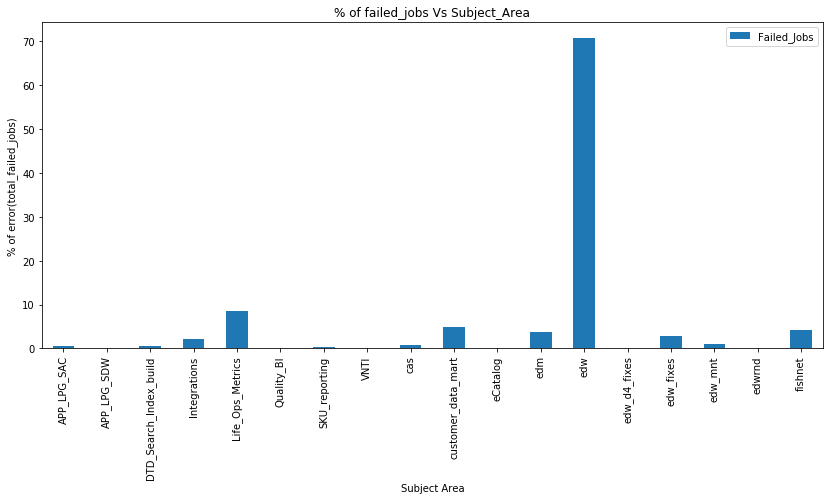

In [120]:
# Visualizing the above Subject_Area using a bar plot
subject_row_wise.plot.bar(label = 'Failed_Jobs',  figsize = (14,6))
plt.xlabel('Subject Area')
plt.ylabel('% of error(total_failed_jobs)')
plt.title('% of failed_jobs Vs Subject_Area')
plt.legend(loc='best')
plt.show()

In [121]:
# Finding out the frequencies of Sessions
info_jobs_unique['SESSION_NAME'].value_counts()

s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION         2840
s_m_FF_STG_START_SOURCE_STG_ap                 358
s_m_FF_P2009_TRAX_PEM_alert                    239
s_m_FF_STG_START_SOURCE_STG_na                 217
s_m_FF_STG_START_SOURCE_STG_eu                 211
                                              ... 
s_m_SAC_775_GEN_LAB_SUPPLY_STG                   1
s_m_EDW_F_INVNTRY_BAL_HIST_update_mer_amt        1
s_m_SAC_671_RL_SLAUGHTER_UK_STG_TO_HISTORY       1
s_m_SAC_800_VWR_EU_BRANDED_STG_TO_HISTORY        1
s_m_SAC_725_SPECTRUM_STG_TO_HISTORY              1
Name: SESSION_NAME, Length: 2026, dtype: int64

In [122]:
# Seggregating based on frequency to other_sessions
info_freq=100
info=dict(zip(*np.unique(info_jobs_unique.SESSION_NAME,return_counts=True)))
info_jobs_unique.SESSION_NAME=info_jobs_unique.SESSION_NAME.apply(lambda x:'Other_Session' if info[x] < info_freq else x)

In [123]:
100. * (info_jobs_unique['SESSION_NAME'].value_counts()) / len(info_jobs_unique)

Other_Session                            90.507203
s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION     4.403715
s_m_FF_STG_START_SOURCE_STG_ap            0.555116
s_m_FF_P2009_TRAX_PEM_alert               0.370594
s_m_FF_STG_START_SOURCE_STG_na            0.336481
s_m_FF_STG_START_SOURCE_STG_eu            0.327177
s_m_LIFEOPS_SCORECRD_DATA_FF              0.279109
s_m_STG_STG_CMGT_USER_CONTACTS            0.277558
s_m_STG_STG_IVGN_USER_CONTACTS            0.277558
s_m_STG_STG_F4801_E1                      0.254299
s_m_EDW_DIM_WEB_USER                      0.220186
s_m_STG_STG_CMGT_ADDRESSES_CMGT           0.218635
s_m_STG_STG_IVGN_ADRRESSES_CMGT           0.218635
s_m_EDW_F_WEB_USER_REGSTR_CYC_CMGT        0.217085
s_m_EDW_T_DSR_PROD_HIER_LKUP_ORD          0.187623
s_m_EDW_DIM_WEB_USER_UpdateEmailKey       0.182971
s_m_STG_STG_AUSP_PO_SAP                   0.181421
s_m_STG_STG_VBEP_SAP                      0.170566
s_m_EDW_F_SLS_ORD_upd_gl_class_cd         0.170566
s_m_STG_STG_F0006_E1           

In [124]:
# Let us use a crosstab
session_ct = pd.crosstab(info_jobs_unique['SESSION_NAME'],info_jobs_unique['RUN_STATUS_CODE']).apply(lambda x:x/x.sum() * 100,axis=1)
session_ct

RUN_STATUS_CODE,0,1
SESSION_NAME,,
Other_Session,3.387072,96.612928
s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,0.035211,99.964789
s_m_EDW_DIM_WEB_USER,16.901408,83.098592
s_m_EDW_DIM_WEB_USER_UpdateEmailKey,0.000000,100.000000
s_m_EDW_F_SLS_ORD_upd_gl_class_cd,0.000000,100.000000
s_m_EDW_F_WEB_USER_REGSTR_CYC_CMGT,15.000000,85.000000
s_m_EDW_T_DSR_PROD_HIER_LKUP_ORD,0.000000,100.000000
s_m_FF_P2009_TRAX_PEM_alert,0.000000,100.000000
s_m_FF_STG_START_SOURCE_STG_ap,7.541899,92.458101


In [125]:
# Failed sessions
sessions_failed = pd.DataFrame(session_ct[0])
sessions_failed

,0
SESSION_NAME,
Other_Session,3.387072
s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,0.035211
s_m_EDW_DIM_WEB_USER,16.901408
s_m_EDW_DIM_WEB_USER_UpdateEmailKey,0.000000
s_m_EDW_F_SLS_ORD_upd_gl_class_cd,0.000000
s_m_EDW_F_WEB_USER_REGSTR_CYC_CMGT,15.000000
s_m_EDW_T_DSR_PROD_HIER_LKUP_ORD,0.000000
s_m_FF_P2009_TRAX_PEM_alert,0.000000
s_m_FF_STG_START_SOURCE_STG_ap,7.541899


    We can see that few sessions have not failed since the error rate is 0.00. So , let's skip such sessions.

In [126]:
sessions_failed = sessions_failed.drop(sessions_failed[sessions_failed[0] == 0.000000].index)
sessions_failed

,0
SESSION_NAME,
Other_Session,3.387072
s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,0.035211
s_m_EDW_DIM_WEB_USER,16.901408
s_m_EDW_F_WEB_USER_REGSTR_CYC_CMGT,15.000000
s_m_FF_STG_START_SOURCE_STG_ap,7.541899
s_m_STG_STG_AUSP_CABN_SAP,20.952381
s_m_STG_STG_F4801_E1,35.975610


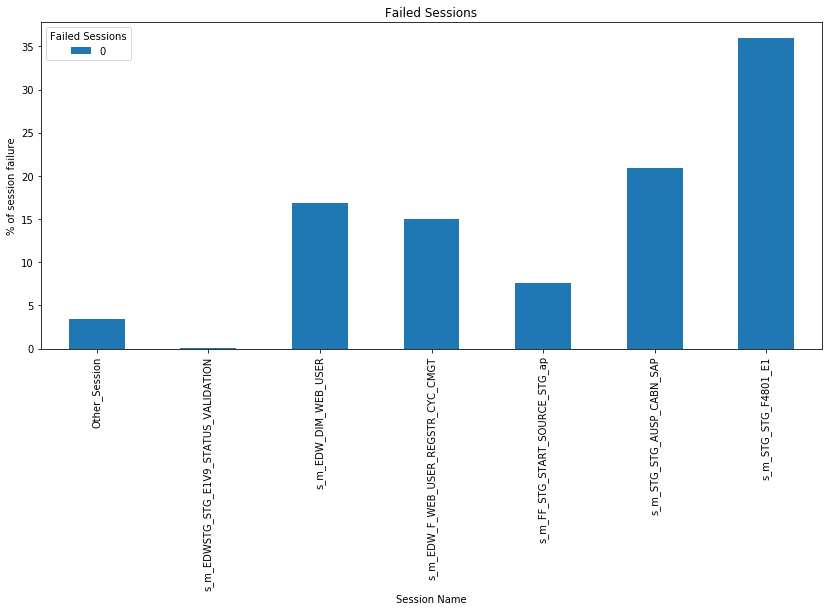

In [127]:
# Visualizing the sessions failed using bar graph
sessions_failed.plot.bar(figsize = (14,6))
plt.title('Failed Sessions')
plt.xlabel('Session Name')
plt.ylabel('% of session failure')
plt.legend(title = 'Failed Sessions')
plt.show()

    From the above graph, we can observe that session "s_m_STG_STG_F4801_E1" is having the max errors followed by "s_m_STG_STG_AUSP_CABN_SAP" and then finally "s_m_EDW_DIM_WEB_USER"

In [128]:
# Similar to finding the sessions we let us find the unique values in a workflow
print(len(info_jobs_unique['WORKFLOW_NAME'].unique()))

219


In [129]:
# Finding out the frequencies of Workflows
info_jobs_unique['WORKFLOW_NAME'].value_counts()

wf_LOAD_PROFILE_CONTACT_OPPOR                             3426
wf_EDWSTG_E1V9_STATUS_VALIDATION                          2871
wf_LOAD_CUST_PROD_SLS_ABI                                 2668
wf_LOAD_OPEX_E1_SAP                                       2584
wf_LOAD_EDM_STAGE_SAP                                     2028
                                                          ... 
wf_STAGE_ON_DEMAND_ABI_FILES                                 1
wf_EDW_SOP_DMND_FCST_ARCHIVE                                 1
wf_EDW_F_WEB_CART_ORD_CMGT_upd_web_cart_attrib_hdr_key       1
wf_STAGE_ON_DEMAND_PRODUCT_HIERARCHY_FF                      1
wf_EDWCM_LOAD_T_CLV_TABLES                                   1
Name: WORKFLOW_NAME, Length: 219, dtype: int64

In [130]:
# Seggregating based on frequency to other_sessions
info_freq=1000
info=dict(zip(*np.unique(info_jobs_unique.WORKFLOW_NAME,return_counts=True)))
info_jobs_unique.WORKFLOW_NAME=info_jobs_unique.WORKFLOW_NAME.apply(lambda x:'Other_Workflow' if info[x] < info_freq else x)

In [131]:
100. * ( info_jobs_unique['WORKFLOW_NAME'].value_counts() / len(info_jobs_unique))

Other_Workflow                          47.225194
wf_LOAD_PROFILE_CONTACT_OPPOR            5.312369
wf_EDWSTG_E1V9_STATUS_VALIDATION         4.451784
wf_LOAD_CUST_PROD_SLS_ABI                4.137011
wf_LOAD_OPEX_E1_SAP                      4.006761
wf_LOAD_EDM_STAGE_SAP                    3.144625
wf_Customer_Data_Mart                    3.062443
wf_STAGE_E1_SALES_ORDER                  2.563148
wf_LOAD_SIEBEL_SR                        2.522833
wf_LOAD_TERR_ASSIGNMENT                  2.521282
wf_LOAD_GENESYS_EU                       2.080911
wf_LOAD_GENESYS_APAC                     2.080911
wf_LOAD_SALES_ORDER_SHIPPING_TRAX_E1     2.001830
wf_LOAD_GENESYS_NA                       1.990975
wf_STAGE_SIEBEL                          1.975469
wf_LOAD_EDM_STAGE_SAP_ROCHESTOR          1.935154
wf_LOAD_PROC_SPEND_SAP                   1.924300
wf_OPS_METRICS                           1.908793
wf_LOAD_BID_APAC_CDW                     1.879332
wf_LOAD_MANUFACTURING_SAP                1.687057


In [132]:
# Comparison of 'Workflow_Name' with 'Run_Status_Code' using crosstab
wf_ct = pd.crosstab(info_jobs_unique['WORKFLOW_NAME'],info_jobs_unique['RUN_STATUS_CODE']).apply(lambda x: x/x.sum() * 100,axis=1)
wf_ct

RUN_STATUS_CODE,0,1
WORKFLOW_NAME,,
Other_Workflow,3.414762,96.585238
wf_Customer_Data_Mart,4.962025,95.037975
wf_EDWSTG_E1V9_STATUS_VALIDATION,1.114594,98.885406
wf_LOAD_BID_APAC_CDW,0.082508,99.917492
wf_LOAD_BPD_APAC_CDW,0.195312,99.804688
wf_LOAD_CUST_PROD_SLS_ABI,6.821589,93.178411
wf_LOAD_EDM_STAGE_SAP,3.846154,96.153846
wf_LOAD_EDM_STAGE_SAP_ROCHESTOR,0.000000,100.000000
wf_LOAD_GENESYS_APAC,0.000000,100.000000


In [133]:
wf_ct_fail = pd.DataFrame(wf_ct[0])
wf_ct_fail

,0
WORKFLOW_NAME,
Other_Workflow,3.414762
wf_Customer_Data_Mart,4.962025
wf_EDWSTG_E1V9_STATUS_VALIDATION,1.114594
wf_LOAD_BID_APAC_CDW,0.082508
wf_LOAD_BPD_APAC_CDW,0.195312
wf_LOAD_CUST_PROD_SLS_ABI,6.821589
wf_LOAD_EDM_STAGE_SAP,3.846154
wf_LOAD_EDM_STAGE_SAP_ROCHESTOR,0.000000
wf_LOAD_GENESYS_APAC,0.000000


In [134]:
# Retaining workflows except 0.000000
workflows_failed = wf_ct_fail.drop(wf_ct_fail[wf_ct_fail[0] == 0.000000].index)
workflows_failed

,0
WORKFLOW_NAME,
Other_Workflow,3.414762
wf_Customer_Data_Mart,4.962025
wf_EDWSTG_E1V9_STATUS_VALIDATION,1.114594
wf_LOAD_BID_APAC_CDW,0.082508
wf_LOAD_BPD_APAC_CDW,0.195312
wf_LOAD_CUST_PROD_SLS_ABI,6.821589
wf_LOAD_EDM_STAGE_SAP,3.846154
wf_LOAD_MANUFACTURING_SAP,9.007353
wf_LOAD_OPEX_E1_SAP,5.882353


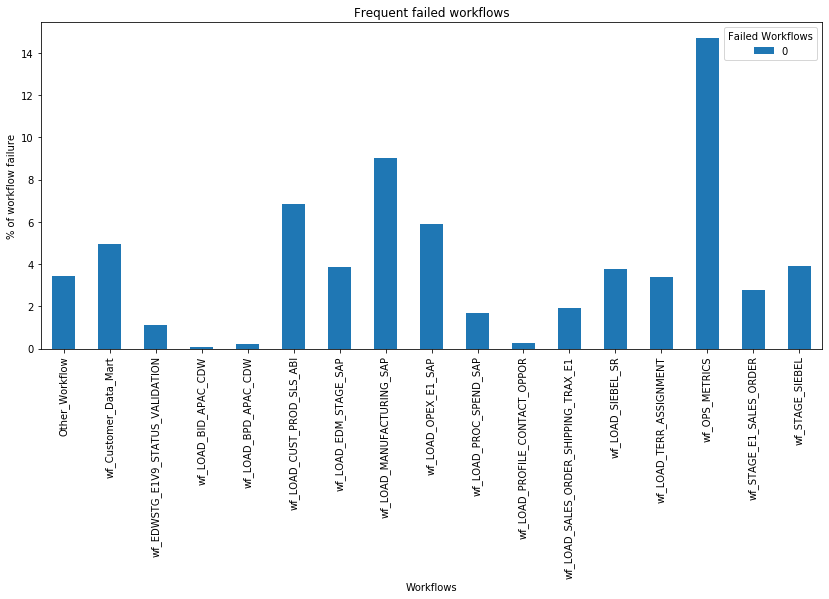

In [135]:
# Let us visualize the workflow by plotting it with a bar plot
workflows_failed.plot.bar(figsize = (14,6))
plt.xlabel('Workflows')
plt.ylabel('% of workflow failure')
plt.title('Frequent failed workflows')
plt.legend(title='Failed Workflows')
plt.show()

    From above graph we can see that workflow wf_OPS_METRICS is failing the most followed by wf_LOAD_MANUFACTURING_SAP.

In [136]:
cols = ['SUCCESSFUL_ROWS','FAILED_ROWS','SUCCESSFUL_SOURCE_ROWS','FAILED_SOURCE_ROWS','FIRST_ERROR_CODE','LAST_ERROR_CODE','TOTAL_ERR']

    Correlation is used only for Numerical Variables not for Categorical variable . Here, RUN_STATUS_CODE is a col which is a categorical variable which shouldn't be included.

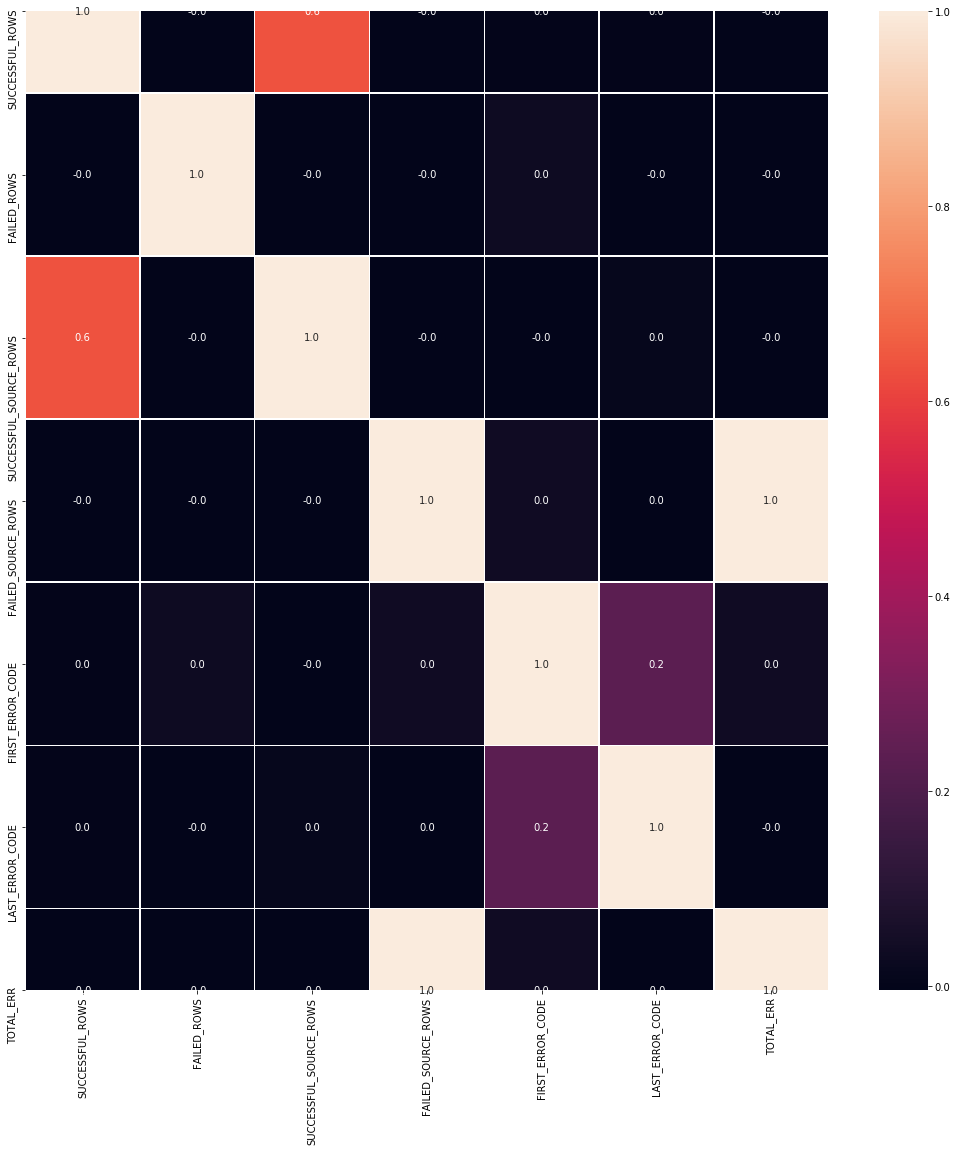

In [137]:
# correlation map
f,ax = plt.subplots(figsize=(18, 18))
sns.heatmap(info_jobs_unique[cols].corr(), annot=True, linewidths=.5, fmt= '.1f',ax=ax)

    From the above heatmap, we can observe that there is a high correlation between 'SUCCESSUL_ROWS' and 'SUCCESSFUL_SOURCE_ROWS' ,also correlation between 'Failed_source_rows' and 'total_err'. 


In [138]:
# Retriving only non-zero values from FIRST_ERROR_CODE
first_error = info_jobs_unique['FIRST_ERROR_CODE'].iloc[info_jobs_unique['FIRST_ERROR_CODE'].nonzero()[0]]
first_error.head(25)

/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:2: FutureWarning: Series.nonzero() is deprecated and will be removed in a future version.Use Series.to_numpy().nonzero() instead
  


65      8229
74      3065
82      8229
85     27031
118     8229
122     8229
143     8229
188     8229
231     8229
314     8229
394     8229
400     8229
415    11131
436    27031
447     8229
451     8229
488     8229
499     3000
539     8229
555     8229
588     8229
629     8229
634     8229
638    21087
644     8229
Name: FIRST_ERROR_CODE, dtype: int64

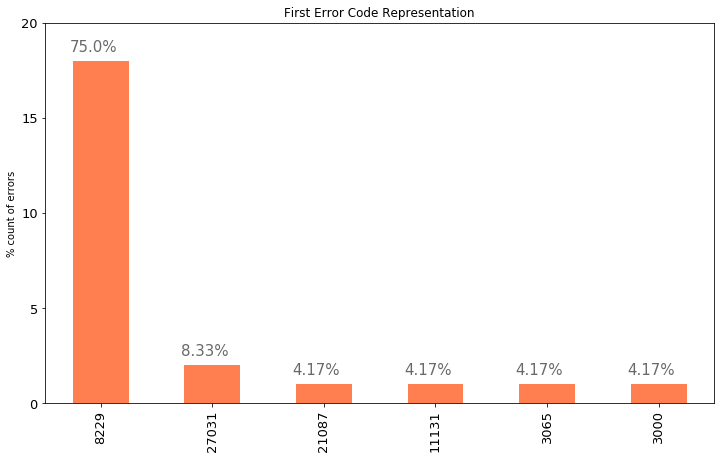

In [139]:
ax = first_error[1:25].value_counts().plot(kind='bar',figsize=(12,7),color='coral',fontsize=13)
ax.set_title('First Error Code Representation')
ax.set_alpha(0.8)
ax.set_ylabel('% count of errors')
ax.set_yticks([0,5,10,15,20])

# Create a list to collect the plt.patches data
totals = []

# find the values and append to the list:
for i in ax.patches:
    totals.append(i.get_height())
    
# set individual bar labels using above list
total = sum(totals)

# set individual bar labels using above list 
for i in ax.patches:
    # get_x pulls left or right; get_height pushes up or down
    ax.text(i.get_x()-.03, i.get_height()+.5, \
            str(round((i.get_height()/total)*100, 2))+'%', fontsize=15,
                color='dimgrey')


    From the graph above we can observe that error code : 8229 is the max which means the error is occuring due to database issues, followed by error code: 21087 (data-conversion errors) and so on... for more about details on error codes you can check the KB article of informatica in the link https://kb.informatica.com/solution

/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:2: FutureWarning: Series.nonzero() is deprecated and will be removed in a future version.Use Series.to_numpy().nonzero() instead
  


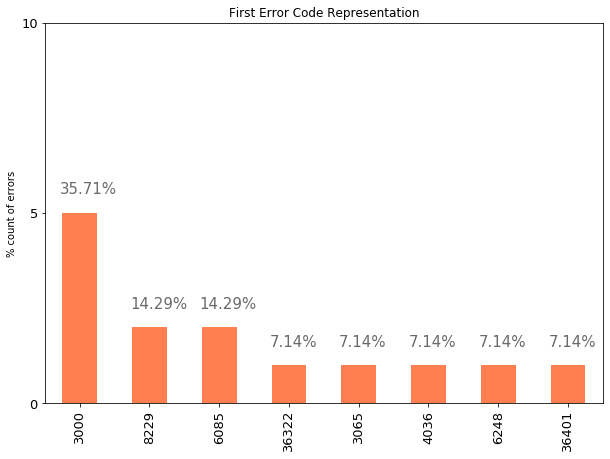

In [140]:
# Let us find out the Last_Error_Code occuring and visualize it through a bar plot
last_error_nz = info_jobs_unique['LAST_ERROR_CODE'].iloc[info_jobs_unique['LAST_ERROR_CODE'].nonzero()[0]]

ax = last_error_nz[1:15].value_counts().plot(kind='bar',figsize=(10,7),color='coral',fontsize=13)
ax.set_title('First Error Code Representation')
ax.set_alpha(0.8)
ax.set_ylabel('% count of errors')
ax.set_yticks([0,5,10])

# Create a list to collect the plt.patches data
totals = []

# find the values and append to the list:
for i in ax.patches:
    totals.append(i.get_height())
    
# set individual bar labels using above list
total = sum(totals)

# set individual bar labels using above list 
for i in ax.patches:
    # get_x pulls left or right; get_height pushes up or down
    ax.text(i.get_x()-.03, i.get_height()+.5, \
            str(round((i.get_height()/total)*100, 2))+'%', fontsize=15,
                color='dimgrey')

    Observation from above graph:-
    1. Err_3000 - Error opening file as such a flat file 
    2. Err_6085 - This issue occurs as there is a mismatch in the datatype along the mapping. 
    3. Err_4035 - This issue occurs due to a mismatch in the data type of a column during the data conversion.

    For more error codes, refer KB article https://kb.informatica.com

    Let's analyse col 'FIRST_ERROR_MSG' by placing it in a dataframe error_msg

In [141]:
error_msg = pd.DataFrame(info_jobs_unique['FIRST_ERROR_MSG'])
error_msg.head()

,FIRST_ERROR_MSG
0,No errors encountered.
1,NaN
2,No errors encountered.
3,No errors encountered.
5,No errors encountered.


In [142]:
error_msg.drop(error_msg[error_msg['FIRST_ERROR_MSG'] == 'No errors encountered.'].index,inplace=True)
error_msg.head()

,FIRST_ERROR_MSG
1,NaN
10,NaN
20,NaN
30,NaN
32,NaN


In [143]:
error_msg['FIRST_ERROR_MSG'].value_counts().head(5)

WRT_8229 Database errors occurred: \nORA-01400: cannot insert NULL into ("EDWSTG"."STG_CMGT_USER_CONTACTS"."LAST_NAME")\n\nDatabase driver error...\nFunction Name : Execute\nSQL Stmt : INSERT INTO STG_CMGT_USER_CONTACTS(USER_KEY,USER_NAME,PASSWORD,UPDATE_DATE,UPDATED_BY,CREATION_DATE,CREATED_BY,CURRENCY,COUNTRY,PRICE_LIST_ID,PARTNER_KEY,STOREFRONT_KEY,ROLES,OWNED_BY,ACCESS_KEY,STATUS,LAST_NAME,FIRST_NAME,TITLE,TITLE_CODE,SUFFIX,EMAIL_ADDRESS,SEX,CERTIFICATION,EMP_STATUS,DEPT_KEY,PAYMENT_TYPE,PAYMENT_NUMBER,PAYMENT_EXPIRATION_DATE,CREDIT_CARD_TYPE,CREDIT_CARD_HOLDER,CREDIT_CARD_HOLDER_FIRST_NAME,CR       178
WRT_8229 Database errors occurred: \nORA-00001: unique constraint (IDQ_STAGE.IDX_AUD_SESSION_INFO_PK_01) violated\n\nDatabase driver error...\nFunction Name : Execute\nSQL Stmt : UPDATE AUD_SESSION_INFO SET SESS_NAME = ?, SESS_START_TIME = ?, SESS_END_TIME = ?, SESS_STATUS = ?, TOTAL_RECORDS_READ = ?, ACTUAL_RECORDS_WRITTEN = ?, SESS_PARAMETER_1 = ?, SESS_PARAMETER_2 = ?, SESS_PARAM

    From the error messages we can observe that the errors mostly occuring are database errors and the errors present are inserting NULL value , unique key constraint, cannot update records
    

In [144]:
#Finding out the Success and failure % in terms of Source and Target rows.
# Success Source Rows
success_source_rows = pd.DataFrame(info_jobs_unique['SUCCESSFUL_SOURCE_ROWS'])

In [145]:
info_jobs_unique['total_rows'] = info_jobs_unique.SUCCESSFUL_SOURCE_ROWS + info_jobs_unique.FAILED_SOURCE_ROWS

In [146]:
info_jobs_unique['percent_success_rows'] = info_jobs_unique.SUCCESSFUL_SOURCE_ROWS / info_jobs_unique.total_rows 

In [147]:
info_jobs_unique.head(20)

,SUBJECT_AREA,SESSION_NAME,SUCCESSFUL_ROWS,FAILED_ROWS,SUCCESSFUL_SOURCE_ROWS,FAILED_SOURCE_ROWS,FIRST_ERROR_CODE,FIRST_ERROR_MSG,LAST_ERROR_CODE,RUN_STATUS_CODE,ACTUAL_START,SESSION_TIMESTAMP,WORKFLOW_NAME,MAPPING_NAME,TOTAL_ERR,total_rows,percent_success_rows
0,edw_fixes,Other_Session,9,0,9,0,0,No errors encountered.,0,1,3/25/2019 0:00,3/25/2019 0:00,Other_Workflow,m_EDWSTG_CPU_UTILIZATION,0,9,1.0
1,edw_fixes,Other_Session,0,0,0,0,0,NaN,0,0,3/25/2019 0:00,3/25/2019 0:00,wf_EDWSTG_E1V9_STATUS_VALIDATION,NaN,0,0,NaN
2,edw_fixes,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,1135,0,1224386,0,0,No errors encountered.,0,1,3/25/2019 0:00,3/25/2019 0:00,wf_EDWSTG_E1V9_STATUS_VALIDATION,m_EDWSTG_STG_E1V9_STATUS_VALIDATION,0,1224386,1.0
3,edw_fixes,s_m_EDWSTG_STG_E1V9_STATUS_VALIDATION,1134,0,1222642,0,0,No errors encountered.,0,1,3/25/2019 0:00,3/25/2019 0:00,wf_EDWSTG_E1V9_STATUS_VALIDATION,m_EDWSTG_STG_E1V9_STATUS_VALIDATION,0,1222642,1.0
5,edw,Other_Session,177761,0,177761,0,0,No errors encountered.,0,1,3/26/2019 0:00,3/26/2019 0:00,Other_Workflow,m_STG_STG_F4102_E1,0,177761,1.0
6,edw,Other_Session,9747,0,9747,0,0,No errors encountered.,0,1,3/26/2019 0:00,3/26/2019 0:00,Other_Workflow,m_STG_STG_F4209_E1,0,9747,1.0
7,edw,Other_Session,73625,0,73625,0,0,No errors encountered.,0,1,3/26/2019 0:00,3/26/2019 0:00,Other_Workflow,m_STG_STG_F1113_E1,0,73625,1.0
8,edw,Other_Session,3034,0,3034,0,0,No errors encountered.,0,1,3/26/2019 0:00,3/26/2019 0:00,Other_Workflow,m_STG_STG_F41002_E1,0,3034,1.0
9,edw,Other_Session,153,0,153,0,0,No errors encountered.,0,1,3/26/2019 0:00,3/26/2019 0:00,Other_Workflow,m_STG_STG_F41001_E1,0,153,1.0
10,edw,Other_Session,0,0,0,0,0,NaN,0,0,3/26/2019 0:00,3/26/2019 0:00,Other_Workflow,NaN,0,0,NaN


In [148]:
info_jobs_unique.groupby(['RUN_STATUS_CODE'])['percent_success_rows'].mean()

RUN_STATUS_CODE
0    0.965218
1    0.999375
Name: percent_success_rows, dtype: float64

In [149]:
info_jobs_unique = info_jobs_unique.drop(['SESSION_NAME','FIRST_ERROR_MSG','WORKFLOW_NAME','MAPPING_NAME','total_rows','percent_success_rows','SESSION_TIMESTAMP','ACTUAL_START'],axis=1)

In [150]:
# Converting categorical features into dummies
# Specify the cols to encode then fit and transform
info_jobs_unique = pd.get_dummies(info_jobs_unique,columns=['SUBJECT_AREA'])

In [151]:
info_jobs_unique.head()

,SUCCESSFUL_ROWS,FAILED_ROWS,SUCCESSFUL_SOURCE_ROWS,FAILED_SOURCE_ROWS,FIRST_ERROR_CODE,LAST_ERROR_CODE,RUN_STATUS_CODE,TOTAL_ERR,SUBJECT_AREA_APP_LPG_SAC,SUBJECT_AREA_APP_LPG_SDW,SUBJECT_AREA_DTD_Search_Index_build,SUBJECT_AREA_Integrations,SUBJECT_AREA_Life_Ops_Metrics,SUBJECT_AREA_Quality_BI,SUBJECT_AREA_SKU_reporting,SUBJECT_AREA_VNTI,SUBJECT_AREA_cas,SUBJECT_AREA_customer_data_mart,SUBJECT_AREA_eCatalog,SUBJECT_AREA_edm,SUBJECT_AREA_edw,SUBJECT_AREA_edw_d4_fixes,SUBJECT_AREA_edw_fixes,SUBJECT_AREA_edw_mnt,SUBJECT_AREA_edwrnd,SUBJECT_AREA_fishnet
0,9,0,9,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
2,1135,0,1224386,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3,1134,0,1222642,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
5,177761,0,177761,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


### Model Building

In [152]:
# Seperating the features from target into X and Y
Y = info_jobs_unique['RUN_STATUS_CODE']
X = info_jobs_unique.drop(['RUN_STATUS_CODE'],axis=1)

In [153]:
X.head()

,SUCCESSFUL_ROWS,FAILED_ROWS,SUCCESSFUL_SOURCE_ROWS,FAILED_SOURCE_ROWS,FIRST_ERROR_CODE,LAST_ERROR_CODE,TOTAL_ERR,SUBJECT_AREA_APP_LPG_SAC,SUBJECT_AREA_APP_LPG_SDW,SUBJECT_AREA_DTD_Search_Index_build,SUBJECT_AREA_Integrations,SUBJECT_AREA_Life_Ops_Metrics,SUBJECT_AREA_Quality_BI,SUBJECT_AREA_SKU_reporting,SUBJECT_AREA_VNTI,SUBJECT_AREA_cas,SUBJECT_AREA_customer_data_mart,SUBJECT_AREA_eCatalog,SUBJECT_AREA_edm,SUBJECT_AREA_edw,SUBJECT_AREA_edw_d4_fixes,SUBJECT_AREA_edw_fixes,SUBJECT_AREA_edw_mnt,SUBJECT_AREA_edwrnd,SUBJECT_AREA_fishnet
0,9,0,9,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
2,1135,0,1224386,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
3,1134,0,1222642,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
5,177761,0,177761,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


In [155]:
# Splitting dataset into train and test
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.3,random_state=0)

In [156]:
# Train the model
# 1. Logistic Regression

logreg=LogisticRegression()
logreg.fit(X_train,Y_train)
# Predict the model
Y_pred = logreg.predict(X_test)
acc_log = logreg.score(X_test,Y_test)
cr_log = classification_report(Y_test,Y_pred)
print("Accuracy of logistic regression classifier on test set : {}".format(acc_log))
print("\n Classification Report of logistic regression classifier on test set\n {}".format(cr_log))

Accuracy of logistic regression classifier on test set : 0.9713665495141617

 Classification Report of logistic regression classifier on test set
               precision    recall  f1-score   support

           0       1.00      0.10      0.19       617
           1       0.97      1.00      0.99     18731

    accuracy                           0.97     19348
   macro avg       0.99      0.55      0.59     19348
weighted avg       0.97      0.97      0.96     19348



In [157]:
# 2. Decision Tree
dtc = DecisionTreeClassifier(max_depth=10,random_state=0)
dtc.fit(X_train,Y_train)
# Predicting the model
Y_pred = dtc.predict(X_test)
acc_dt = dtc.score(X_test,Y_test)
cr_dt = classification_report(Y_test,Y_pred)
print("Accuracy of Decision Tree classifier on test set : {}".format(acc_dt))
print("\n Classification Report of Decision Tree classifier on test set\n {}".format(cr_dt))


Accuracy of Decision Tree classifier on test set : 0.9756047136654952

 Classification Report of Decision Tree classifier on test set
               precision    recall  f1-score   support

           0       0.86      0.28      0.42       617
           1       0.98      1.00      0.99     18731

    accuracy                           0.98     19348
   macro avg       0.92      0.64      0.71     19348
weighted avg       0.97      0.98      0.97     19348



In [158]:
# 3. Random Forest
from sklearn.ensemble import RandomForestClassifier
RFC = RandomForestClassifier(n_estimators=250,max_depth=12,max_features = 3,random_state=0)
RFC.fit(X_train,Y_train)
# Predicting the model
Y_pred = RFC.predict(X_test)
acc_RF = RFC.score(X_test,Y_test)
cr_rf = classification_report(Y_test,Y_pred)
print("Accuracy of Random Forest classifier on test set : {}".format(acc_RF))
print("\n Classification Report of Random Forest classifier on test set\n {}".format(cr_rf))

Accuracy of Random Forest classifier on test set : 0.975914823237544

 Classification Report of Random Forest classifier on test set
               precision    recall  f1-score   support

           0       0.90      0.27      0.42       617
           1       0.98      1.00      0.99     18731

    accuracy                           0.98     19348
   macro avg       0.94      0.64      0.70     19348
weighted avg       0.97      0.98      0.97     19348



In [159]:
# 4. KNN
KN = KNeighborsClassifier()
KN.fit(X_train,Y_train)
# Predicting the model
Y_pred = KN.predict(X_test)
acc_KNN = KN.score(X_test,Y_test)
cr_KNN = classification_report(Y_test,Y_pred)
print("Accuracy of KNearest Neighbors Classifier on test set : {}".format(acc_KNN))
print("\n Classification Report of KNearest Neigbors classifier on test set\n {}".format(cr_KNN))


Accuracy of KNearest Neighbors Classifier on test set : 0.9750878643787472

 Classification Report of KNearest Neigbors classifier on test set
               precision    recall  f1-score   support

           0       0.89      0.25      0.39       617
           1       0.98      1.00      0.99     18731

    accuracy                           0.98     19348
   macro avg       0.94      0.62      0.69     19348
weighted avg       0.97      0.98      0.97     19348



In [160]:
# Representing the accuracries on a dataframe
accuracy = pd.DataFrame({
    'Model':['Logistic Regression','Decision Trees','Random Forest','KNN'],
    'Score':[acc_log,acc_dt,acc_RF,acc_KNN]
})
acc_df = accuracy.sort_values(by='Score',ascending=False)
acc_df = acc_df.set_index('Score')
acc_df

,Model
Score,
0.975915,Random Forest
0.975605,Decision Trees
0.975088,KNN
0.971367,Logistic Regression


    Should we consider RandomForest as our final model in production?

    Performance is the best for RandomForest among all others but it is to be noted that this performance is on a single iteration. What if our model is overfitting? That is why it is always a good practice to try cross-validation on models

In [162]:
# Let us try to using K-Fold cross validation for splitting train and test data
# Logistic Regression
lr_score = cross_val_score(logreg, X_train, Y_train, cv=10, scoring='accuracy')
print("Scores:", lr_score)
print("Mean:",lr_score.mean())
print("Standard Deviation",lr_score.std())

/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/sklearn/linear_model/_logistic.py:940: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  extra_warning_msg=_LOGISTIC_SOLVER_CONVERGENCE_MSG)
/Users/gurumanikanta/anaconda3/lib/python3.7/site-packages/sklearn/linear_model/_logistic.py:940: ConvergenceWarning: lbfgs failed to converge (status=2):
ABNORMAL_TERMINATION_IN_LNSRCH.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_mode

Scores: [0.9696567  0.97054264 0.9696567  0.97053611 0.97097918 0.96987151
 0.97031458 0.97031458 0.96964998 0.96964998]
Mean: 0.9701171941507436
Standard Deviation 0.00045809121743501145


    Our model has an average accuracy of 97% and a standard deviation of 0

In [163]:
# Decision Tree
dt_score = cross_val_score(dtc, X_train, Y_train, cv=10, scoring='accuracy')
print("Scores:", dt_score)
print("Mean:",dt_score.mean())
print("Standard Deviation",dt_score.std())

Scores: [0.97320044 0.97497231 0.97452935 0.97629597 0.9765175  0.9758529
 0.97540984 0.97474524 0.97563137 0.9745237 ]
Mean: 0.9751678621598561
Standard Deviation 0.0009352565939038846


    Here, we get an accuracy of 97.5% and std. deviation of 0%.

In [164]:
# Random Forest
RF_score = cross_val_score(RFC, X_train, Y_train, cv=10, scoring='accuracy')
print("Scores:", RF_score)
print("Mean:",RF_score.mean())
print("Standard Deviation",RF_score.std())

Scores: [0.97297896 0.97497231 0.97475083 0.97563137 0.97673903 0.97496677
 0.9751883  0.97474524 0.97563137 0.97496677]
Mean: 0.9750570956556469
Standard Deviation 0.0008966004413403423


    we obtain an average accuracy of 97.5% and a std. deviation of 0%.

In [165]:
# KNN
KNN_score = cross_val_score(KN, X_train, Y_train, cv=10, scoring='accuracy')
print("Scores:", KNN_score)
print("Mean:",KNN_score.mean())
print("Standard Deviation",KNN_score.std())

Scores: [0.97120709 0.97275748 0.97386489 0.97385911 0.96278245 0.97363757
 0.97430217 0.97341604 0.97540984 0.97408064]
Mean: 0.9725317273048877
Standard Deviation 0.00340903539744524


    In KNN cross-validation, we obtain an average accuracy of 97.2% and a std. deviation of 0%.

#### Accuracies of algo's after cross-validation

In [166]:
results_cv = pd.DataFrame({
    'Model':['Logistic Regression','Decision Trees','Random Forest','KNN'],
    'Score':[lr_score.mean(),dt_score.mean(),RF_score.mean(),KNN_score.mean()]
})
res_df = results_cv.sort_values(by='Score',ascending=False)
res_df = res_df.set_index('Score')
res_df

,Model
Score,
0.975168,Decision Trees
0.975057,Random Forest
0.972532,KNN
0.970117,Logistic Regression


    From where do we determine the feature importances?

    It is preferred to check the importances from the best performing model on cross validation. So we would pick the importances from DecisionTree. Had our Logistic model been the best performing, we would instead look for the coefficients.

<Figure size 36000x720 with 0 Axes>

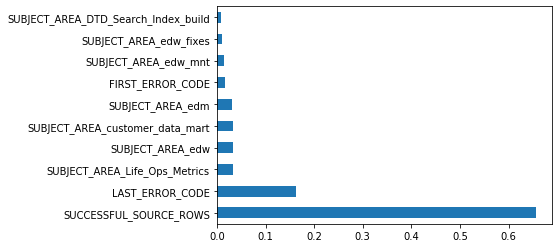

<Figure size 36000x720 with 0 Axes>

In [167]:
feature_importance = pd.Series(dtc.feature_importances_,index=X.columns)
feature_importance = feature_importance.nlargest(10)
feature_importance.plot(kind='barh')
plt.figure(figsize=(500,10))

## Conclusion
    We now have a stable model that can be used in production. The next steps will be to improve the performance using hyperparameter tuning, increasing data if possible and using complex models. 
    When closely monitered accuracies very near to 100 are also reliable. However, don't stop here there's still lots of unexplored waters. We encourage you to try different approaches to solve this problem